# SST Image for 2025-02-04T03:12:20Z

In [1]:
from importlib import reload

import numpy as np
from numpy import ma
import xarray
import healpy

from copy import deepcopy

from matplotlib import pyplot as plt
import cartopy.crs as ccrs

from remote_sensing.download import podaac
from remote_sensing.healpix import rs_healpix
from remote_sensing.healpix import plotting as hp_plotting
from remote_sensing.healpix import utils as hp_utils
from remote_sensing.healpix import combine as hp_combine
from remote_sensing import io as rs_io
from remote_sensing import units
from remote_sensing import kml as rs_kml

In [2]:
%matplotlib ipympl

In [3]:
xlim = (127.,134)
ylim = (18.,23)

# Save dict (to avoid repeating some steps if you come back)

In [5]:
sdict = {}
#sdict = rs_io.loadjson('SST_2025-02-04T03.json')

# Download the past day of files in the region

## Grab em

## AMSR2

In [6]:
amsr2_files, _ = podaac.grab_file_list('AMSR2-REMSS-L2P_RT-v8.2', dt_past=dict(days=2),
                                             bbox='127,18,134,23')
amsr2_files

['https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/AMSR2-REMSS-L2P_RT-v8.2/20250203160512-REMSS-L2P_GHRSST-SSTsubskin-AMSR2-L2B_rt_r67644-v02.0-fv01.0.nc',
 'https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/AMSR2-REMSS-L2P_RT-v8.2/20250203043301-REMSS-L2P_GHRSST-SSTsubskin-AMSR2-L2B_rt_r67637-v02.0-fv01.0.nc',
 'https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/AMSR2-REMSS-L2P_RT-v8.2/20250202034948-REMSS-L2P_GHRSST-SSTsubskin-AMSR2-L2B_rt_r67622-v02.0-fv01.0.nc']

## H09

In [7]:
h09_files, _ = podaac.grab_file_list('H09-AHI-L3C-ACSPO-v2.90', dt_past=dict(days=1),
                                             bbox='127,18,134,23')
h09_files[0:2]

['https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/H09-AHI-L3C-ACSPO-v2.90/20250204000000-STAR-L3C_GHRSST-SSTsubskin-AHI_H09-ACSPO_V2.90-v02.0-fv01.0.nc',
 'https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/H09-AHI-L3C-ACSPO-v2.90/20250203230000-STAR-L3C_GHRSST-SSTsubskin-AHI_H09-ACSPO_V2.90-v02.0-fv01.0.nc']

## Download em

In [8]:
reload(podaac)
local_amsr2 = podaac.download_files(amsr2_files, verbose=False)

Using default download directory: /home/xavier/Projects/Oceanography/data/Remote_Sensing/PODAAC
Downloaded 0 files, failed on 0 files, skipped 3 existing files.


In [9]:
local_h09 = podaac.download_files(h09_files, verbose=False)

Using default download directory: /home/xavier/Projects/Oceanography/data/Remote_Sensing/PODAAC
Downloaded 17 files, failed on 0 files, skipped 4 existing files.


In [10]:
sdict['local_amsr2'] = local_amsr2
sdict['local_h09'] = local_h09
# 
jdict = rs_io.jsonify(sdict)
rs_io.savejson('SST_2025-02-04T03.json', jdict, overwrite=True)

# Generate RS_Healpix objects

## AMSR2

In [11]:
reload(rs_healpix)
amsr2_hpxs = []
for data_file in sdict['local_amsr2'][0:1]:
    # Objectify
    rs_hpx = rs_healpix.RS_Healpix.from_dataset_file(
        data_file, 'sea_surface_temperature',
        time_isel=0, resol_km=11., 
        lat_slice=(18,23.),  lon_slice=(127., 134.))
    # 
    print(f"Generated RS_Healpix from {data_file}")
    # Add
    amsr2_hpxs.append(rs_hpx)

Generated RS_Healpix from /home/xavier/Projects/Oceanography/data/Remote_Sensing/PODAAC/AMSR2-REMSS-L2P_RT-v8.2/20250203160512-REMSS-L2P_GHRSST-SSTsubskin-AMSR2-L2B_rt_r67644-v02.0-fv01.0.nc


In [12]:
amsr2_hpxs[0]

<RS_Healpix: nside=512, resol=0.11451621372724687deg
 file=20250203160512-REMSS-L2P_GHRSST-SSTsubskin-AMSR2-L2B_rt_r67644-v02.0-fv01.0.nc, var="sea_surface_temperature">

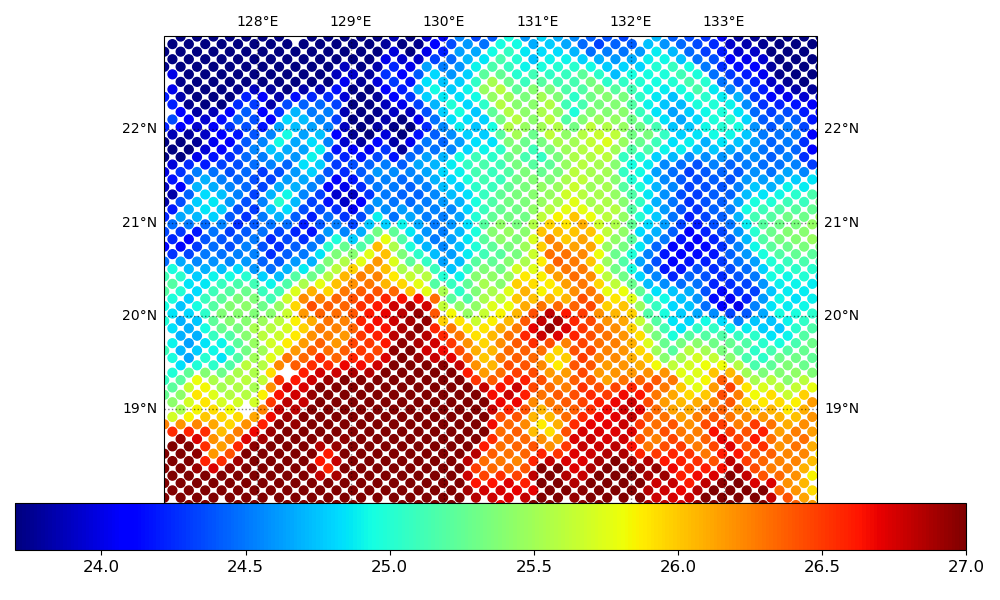

In [13]:
amsr2_hpxs[0].plot(figsize=(10.,6), cmap='jet', xlim=xlim, ylim=ylim,
              projection='platecarree', ssize=40., vmin=23.7, vmax=27.)

## Himawari

In [18]:
reload(rs_healpix)
h09_hpxs = []
# The last 10 hours have been very cloudy
# Using the previous 10
for data_file in sdict['local_h09'][10:20]:
    # Objectify
    rs_hpx = rs_healpix.RS_Healpix.from_dataset_file(
        data_file, 'sea_surface_temperature',
        lat_slice=slice(23,18),  lon_slice=slice(127., 134.), time_isel=0)
    # 
    print(f"Generated RS_Healpix from {data_file}")
    # Add
    h09_hpxs.append(rs_hpx)
    del(rs_hpx)

Generated RS_Healpix from /home/xavier/Projects/Oceanography/data/Remote_Sensing/PODAAC/H09-AHI-L3C-ACSPO-v2.90/20250203140000-STAR-L3C_GHRSST-SSTsubskin-AHI_H09-ACSPO_V2.90-v02.0-fv01.0.nc
Generated RS_Healpix from /home/xavier/Projects/Oceanography/data/Remote_Sensing/PODAAC/H09-AHI-L3C-ACSPO-v2.90/20250203130000-STAR-L3C_GHRSST-SSTsubskin-AHI_H09-ACSPO_V2.90-v02.0-fv01.0.nc
Generated RS_Healpix from /home/xavier/Projects/Oceanography/data/Remote_Sensing/PODAAC/H09-AHI-L3C-ACSPO-v2.90/20250203120000-STAR-L3C_GHRSST-SSTsubskin-AHI_H09-ACSPO_V2.90-v02.0-fv01.0.nc
Generated RS_Healpix from /home/xavier/Projects/Oceanography/data/Remote_Sensing/PODAAC/H09-AHI-L3C-ACSPO-v2.90/20250203110000-STAR-L3C_GHRSST-SSTsubskin-AHI_H09-ACSPO_V2.90-v02.0-fv01.0.nc
Generated RS_Healpix from /home/xavier/Projects/Oceanography/data/Remote_Sensing/PODAAC/H09-AHI-L3C-ACSPO-v2.90/20250203100000-STAR-L3C_GHRSST-SSTsubskin-AHI_H09-ACSPO_V2.90-v02.0-fv01.0.nc
Generated RS_Healpix from /home/xavier/Projects/Oc

# Average Himawari

In [30]:
reload(rs_healpix)
h09_stack = rs_healpix.RS_Healpix.from_list(h09_hpxs)
h09_stack

<RS_Healpix: nside=2048, resol=0.028629053431811716deg
 file=Avg[20250203140000-STAR-L3C_GHRSST-SSTsubskin-AHI_H09-ACSPO_V2.90-v02.0-fv01.0.nc-20250203050000-STAR-L3C_GHRSST-SSTsubskin-AHI_H09-ACSPO_V2.90-v02.0-fv01.0.nc], var="sea_surface_temperature">

(<GeoAxes: >, <matplotlib.collections.PathCollection at 0x73a83c2800e0>)

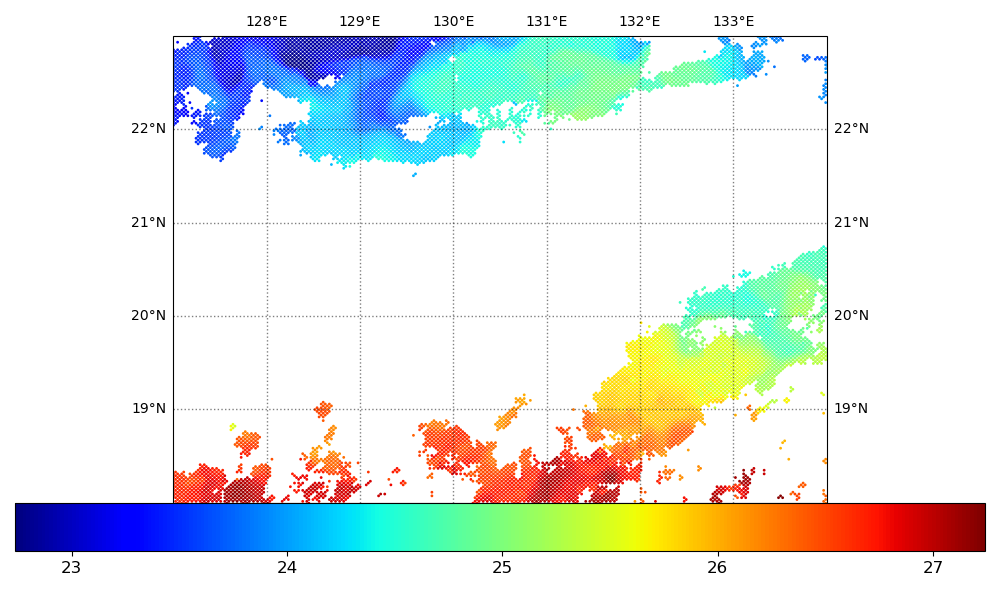

In [31]:
h09_stack.plot(figsize=(10.,6), cmap='jet', xlim=xlim, ylim=ylim,
              projection='platecarree')

# Fill in the gaps

In [32]:
h09_stack.fill_in(amsr2_hpxs[0], (xlim[0], xlim[1], ylim[0], ylim[1]))

Filled in 469852046065 pixels


(<GeoAxes: >, <matplotlib.collections.PathCollection at 0x73a83c29dac0>)

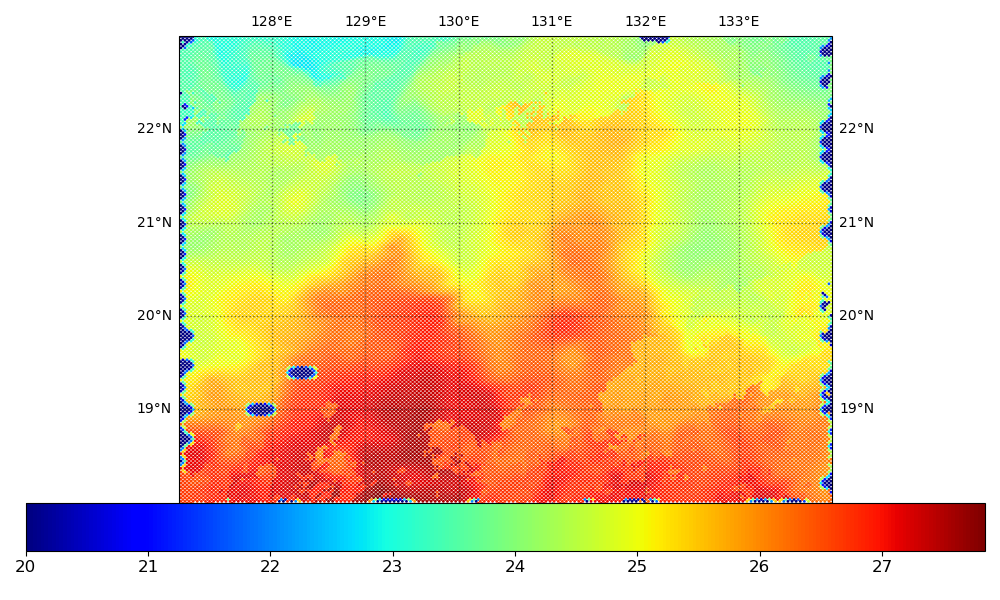

In [33]:
h09_stack.plot(figsize=(10.,6), cmap='jet', xlim=xlim, ylim=ylim,
              projection='platecarree', vmin=20.)

# KML me

## Main figure without colorbar

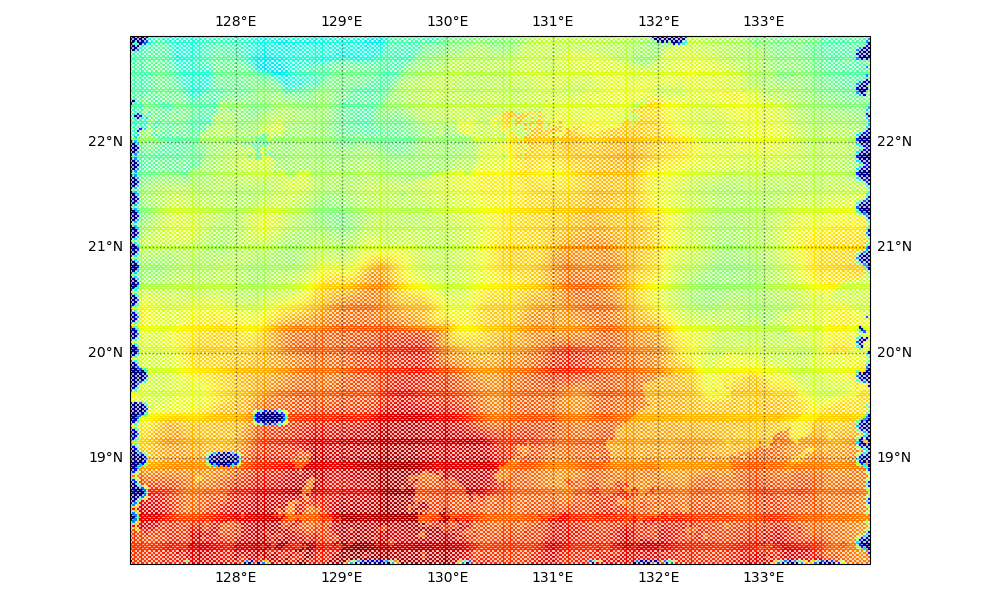

In [47]:
ax, img = h09_stack.plot(figsize=(10.,6), cmap='jet', xlim=xlim, ylim=ylim, add_colorbar=False,
              projection='platecarree', vmin=20., savefig='kml_test.png', dpi=1200, marker=',')

/home/xavier/Projects/Oceanography/python/remote_sensing/remote_sensing/kml.py:16: UserWarning: Adding colorbar to a different Figure <Figure size 1000x600 with 1 Axes> than <Figure size 100x400 with 1 Axes> which fig.colorbar is called on.
  cb = fig.colorbar(im, cax=ax)


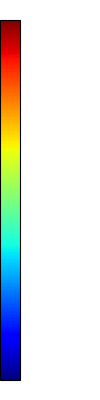

In [41]:
reload(rs_kml)
rs_kml.colorbar(img, 'SST (C)', 'colorbar.png')

In [43]:
lon_min, lon_max = xlim
lat_min, lat_max = ylim

reload(rs_kml)
rs_kml.make_kml(llcrnrlon=lon_min, llcrnrlat=lat_min,
        urcrnrlon=lon_max, urcrnrlat=lat_max,
        figs=['kml_test.png'], colorbar='colorbar.png',
        kmzfile='small_dots.kmz', name='Merged SST')

----

In [48]:
viirs_files, _ = podaac.grab_file_list('N21-VIIRS-L2P-ACSPO-v2.80',
                                       dt_past=dict(days=1), bbox='127,18,134,23')
viirs_files

['https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/N21-VIIRS-L2P-ACSPO-v2.80/20250204045000-STAR-L2P_GHRSST-SSTsubskin-VIIRS_N21-ACSPO_V2.80-v02.0-fv01.0.nc',
 'https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/N21-VIIRS-L2P-ACSPO-v2.80/20250204031000-STAR-L2P_GHRSST-SSTsubskin-VIIRS_N21-ACSPO_V2.80-v02.0-fv01.0.nc',
 'https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/N21-VIIRS-L2P-ACSPO-v2.80/20250203174000-STAR-L2P_GHRSST-SSTsubskin-VIIRS_N21-ACSPO_V2.80-v02.0-fv01.0.nc',
 'https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/N21-VIIRS-L2P-ACSPO-v2.80/20250203160000-STAR-L2P_GHRSST-SSTsubskin-VIIRS_N21-ACSPO_V2.80-v02.0-fv01.0.nc']

In [49]:
local_viirs = podaac.download_files(viirs_files, verbose=False)

Using default download directory: /home/xavier/Projects/Oceanography/data/Remote_Sensing/PODAAC
Creating directory: /home/xavier/Projects/Oceanography/data/Remote_Sensing/PODAAC/N21-VIIRS-L2P-ACSPO-v2.80
Downloaded 4 files, failed on 0 files, skipped 0 existing files.


In [ ]:
reload(rs_healpix)
viirs_hpxs = []
for data_file in local_viirs[0:2]:
    # Objectify
    rs_hpx = rs_healpix.RS_Healpix.from_dataset_file(
        data_file, 'sea_surface_temperature',
        lat_slice=(18,23),  lon_slice=(127., 134.), time_isel=0,
        resol_km=1.)
    # 
    print(f"Generated RS_Healpix from {data_file}")
    # Add
    viirs_hpxs.append(rs_hpx)
    del(rs_hpx)
# Stack
viirs_stack = rs_healpix.RS_Healpix.from_list(viirs_hpxs)

Generated RS_Healpix from /home/xavier/Projects/Oceanography/data/Remote_Sensing/PODAAC/N21-VIIRS-L2P-ACSPO-v2.80/20250204045000-STAR-L2P_GHRSST-SSTsubskin-VIIRS_N21-ACSPO_V2.80-v02.0-fv01.0.nc
Python 3.12.2 | packaged by conda-forge | (main, Feb 16 2024, 20:50:58) [GCC 12.3.0]
Type 'copyright', 'credits' or 'license' for more information
IPython 8.29.0 -- An enhanced Interactive Python. Type '?' for help.


get_nside_from_dataset 142



(<GeoAxes: >, <matplotlib.collections.PathCollection at 0x73a837e45bb0>)

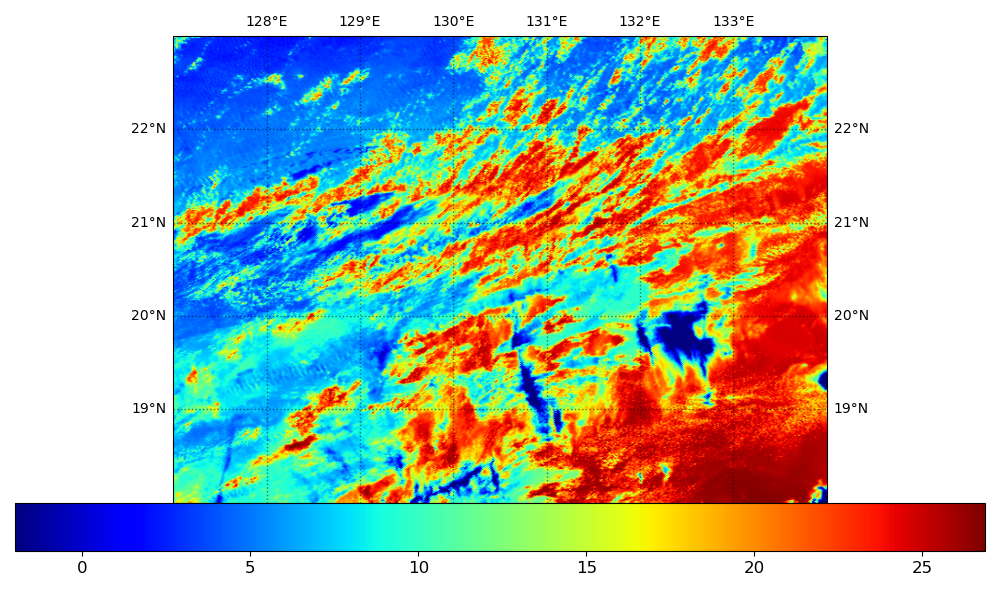

In [56]:
viirs_stack.plot(figsize=(10.,6), cmap='jet', xlim=xlim, ylim=ylim,
              projection='platecarree')

In [57]:
ds = xarray.open_dataset(local_viirs[0])
ds

<xarray.Dataset> Size: 995MB
Dimensions:                  (time: 1, nj: 5360, ni: 3200)
Coordinates:
  * time                     (time) datetime64[ns] 8B 2025-02-04T04:50:01
    lat                      (nj, ni) float32 69MB ...
    lon                      (nj, ni) float32 69MB ...
Dimensions without coordinates: nj, ni
Data variables:
    sst_dtime                (time, nj, ni) timedelta64[ns] 137MB ...
    dt_analysis              (time, nj, ni) float32 69MB ...
    satellite_zenith_angle   (time, nj, ni) float32 69MB ...
    sea_surface_temperature  (time, nj, ni) float32 69MB ...
    sses_bias                (time, nj, ni) float32 69MB ...
    sses_standard_deviation  (time, nj, ni) float32 69MB ...
    sea_ice_fraction         (time, nj, ni) float32 69MB ...
    l2p_flags                (time, nj, ni) int16 34MB ...
    quality_level            (time, nj, ni) float32 69MB ...
    wind_speed               (time, nj, ni) float32 69MB ...
    sst_gradient_magnitude   (time, nj, ni) float32 69MB ...
    sst_front_position       (time, nj, ni) float32 69MB ...
Attributes: (12/59)
    geospatial_bounds:                        POLYGON(( 136.836  36.961,  142...
    geospatial_first_scanline_first_fov_lat:  2.4824426
    geospatial_first_scanline_first_fov_lon:  142.1862
    geospatial_first_scanline_last_fov_lat:   -1.5799003
    geospatial_first_scanline_last_fov_lon:   115.450386
    geospatial_last_scanline_first_fov_lat:   36.961464
    ...                                       ...
    time_coverage_end:                        20250204T045959Z
    time_coverage_start:                      20250204T045000Z
    title:                                    VIIRS L2P SST
    uuid:                                     9b5af574-e2c1-11ef-808d-ecf4bbe...
    westernmost_longitude:                    104.42486
    netcdf_version_id:                        4.7.4 of Nov 18 2021 15:43:53 $

In [58]:
ds.quality_level

<xarray.DataArray 'quality_level' (time: 1, nj: 5360, ni: 3200)> Size: 69MB
[17152000 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 8B 2025-02-04T04:50:01
    lat      (nj, ni) float32 69MB ...
    lon      (nj, ni) float32 69MB ...
Dimensions without coordinates: nj, ni
Attributes:
    comment:                SST quality levels: 5 corresponds to clear-sky pi...
    flag_meanings:          missing invalid not_used not_used not_used clear
    flag_values:            [0 1 2 3 4 5]
    long_name:              quality level of SST pixel
    valid_max:              5
    valid_min:              0
    coverage_content_type:  qualityInformation

In [59]:
ds.attrs

{'geospatial_bounds': 'POLYGON(( 136.836  36.961,  142.186   2.482,  115.450  -1.580,  104.425  32.062,  136.836  36.961))',
 'geospatial_first_scanline_first_fov_lat': np.float32(2.4824426),
 'geospatial_first_scanline_first_fov_lon': np.float32(142.1862),
 'geospatial_first_scanline_last_fov_lat': np.float32(-1.5799003),
 'geospatial_first_scanline_last_fov_lon': np.float32(115.450386),
 'geospatial_last_scanline_first_fov_lat': np.float32(36.961464),
 'geospatial_last_scanline_first_fov_lon': np.float32(136.83589),
 'geospatial_last_scanline_last_fov_lat': np.float32(32.061626),
 'geospatial_last_scanline_last_fov_lon': np.float32(104.42486),
 'Conventions': 'CF-1.7, ACDD-1.3',
 'acknowledgement': 'Please acknowledge the use of these data with the following statement: These data were provided by Group for High Resolution Sea Surface Temperature (GHRSST) and the National Oceanic and Atmospheric Administration (NOAA).',
 'cdm_data_type': 'swath',
 'comment': 'none',
 'creator_email': 